# Eksploracja danych — Laboratorium 1
## Python do analizy danych: przypomnienie

**Cel zajęć:** odświeżyć Pythona i poznać podstawy narzędzi, których będziemy używać przez cały semestr: **NumPy**, **pandas** i **matplotlib**.

**Plan:**
1. Python w pigułce
2. NumPy
3. pandas — pierwsze kroki
4. Wykresy w matplotlib

**Zadania** mają dwa poziomy:
- 🟢 **podstawowe** — obowiązkowe,
- 🔵 **dla ambitnych** — dodatkowe.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, rozwiąż zadania w miejscach oznaczonych `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 12})

---
# 1. Python w pigułce

In [2]:
# Listy, indeksowanie i wycinanie (slicing)
temperatury = [12.5, 14.0, 9.8, 17.3, 15.1]

print(temperatury[0])     # pierwszy element
print(temperatury[-1])    # ostatni element
print(temperatury[1:3])   # elementy o indeksach 1 i 2
print(len(temperatury))

12.5
15.1
[14.0, 9.8]
5


In [3]:
# Pętla for, enumerate i zip
dni = ["pon", "wt", "śr", "czw", "pt"]

for i, t in enumerate(temperatury):
    print(f"[{i}] -> {t}")

for dzien, t in zip(dni, temperatury):
    print(f"{dzien}: {t:.1f} °C")   # :.1f — jedna cyfra po przecinku

[0] -> 12.5
[1] -> 14.0
[2] -> 9.8
[3] -> 17.3
[4] -> 15.1
pon: 12.5 °C
wt: 14.0 °C
śr: 9.8 °C
czw: 17.3 °C
pt: 15.1 °C


In [4]:
# Słownik: klucz -> wartość
miasto = {"nazwa": "Łódź", "wojewodztwo": "łódzkie", "ludnosc_2021": 670_642}

print(miasto["nazwa"])
for klucz, wartosc in miasto.items():
    print(klucz, "=", wartosc)

Łódź
nazwa = Łódź
wojewodztwo = łódzkie
ludnosc_2021 = 670642


In [5]:
# Funkcja z docstringiem
def potega(lista, p):
    """
    Podnosi każdy element listy do potęgi p.

    Parametry:
    - lista (list): lista liczb,
    - p (int | float): wykładnik.

    Zwraca:
    - list: nowa lista z elementami podniesionymi do potęgi p.
    """
    wynik = []
    for x in lista:
        wynik.append(x ** p)
    return wynik


print(potega([1, 2, 3, 4], 3))
help(potega)   # w Jupyterze/Colabie także: potega?

[1, 8, 27, 64]
Help on function potega in module __main__:

potega(lista, p)
    Podnosi każdy element listy do potęgi p.
    
    Parametry:
    - lista (list): lista liczb,
    - p (int | float): wykładnik.
    
    Zwraca:
    - list: nowa lista z elementami podniesionymi do potęgi p.



### List comprehension

Zwięzły sposób tworzenia list:
```python
[wyrażenie for element in kolekcja if warunek]
```

In [6]:
print([x ** 2 for x in range(6)])
print([x ** 2 for x in range(6) if x % 2 == 0])

[0, 1, 4, 9, 16, 25]
[0, 4, 16]


### 🟢 Zadanie 1: średnia i mediana

Lista `dlugosc_zycia` zawiera oczekiwaną długość życia (w latach) w 14 krajach.

1. Napisz funkcję `srednia(liczby)`, która zwraca średnią arytmetyczną — **bez** używania `sum()` i NumPy (użyj pętli).
2. Napisz funkcję `mediana(liczby)`, która zwraca medianę. Pamiętaj o przypadku parzystej i nieparzystej liczby elementów. Wskazówka: `sorted()`.
3. Porównaj wyniki z `np.mean()` i `np.median()`.

🔵 **Dla ambitnych:** niech obie funkcje zgłaszają czytelny błąd (`raise ValueError(...)`), gdy lista jest pusta.

In [8]:
dlugosc_zycia = [81.8, 81.0, 82.6, 83.0, 81.8, 84.3, 82.8, 81.9, 82.2, 82.0, 82.7, 79.8, 83.3, 82.0]

In [10]:
def srednia(liczby):
    """Zwraca średnią arytmetyczną listy liczb (bez sum() i NumPy)."""
    if len(liczby) == 0:
        raise ValueError("Nie można policzyć średniej z pustej listy.")
    suma = 0
    for x in liczby:
        suma += x
    return suma / len(liczby)


def mediana(liczby):
    """Zwraca medianę listy liczb."""
    if len(liczby) == 0:
        raise ValueError("Nie można policzyć mediany z pustej listy.")
    s = sorted(liczby)
    n = len(s)
    srodek = n // 2
    if n % 2 == 1:                      # nieparzysta liczba elementów
        return s[srodek]
    return (s[srodek - 1] + s[srodek]) / 2   # parzysta: średnia dwóch środkowych


print("moja średnia:", srednia(dlugosc_zycia), " NumPy:", np.mean(dlugosc_zycia))
print("moja mediana:", mediana(dlugosc_zycia), " NumPy:", np.median(dlugosc_zycia))

# 🔵 test pustej listy
try:
    srednia([])
except ValueError as e:
    print("Błąd:", e)

moja średnia: 82.22857142857143  NumPy: 82.22857142857143
moja mediana: 82.1  NumPy: 82.1
Błąd: Nie można policzyć średniej z pustej listy.


### 🟢 Zadanie 2: zliczanie

Napisz funkcję `zlicz(lista)`, która zwraca słownik: element → liczba jego wystąpień.

Przykład: `zlicz(["a", "b", "a", "c", "a"])` → `{"a": 3, "b": 1, "c": 1}`

Sprawdź ją na liście `oceny`. Która ocena występuje najczęściej?

In [11]:
oceny = [4, 3, 5, 4, 4, 2, 3, 5, 4, 3, 4, 5, 3, 4]

def zlicz(lista):
    """Zwraca słownik: element -> liczba jego wystąpień."""
    wynik = {}
    for el in lista:
        wynik[el] = wynik.get(el, 0) + 1
    return wynik

licznik = zlicz(oceny)
print(licznik)
najczestsza = max(licznik, key=licznik.get)
print("Najczęstsza ocena:", najczestsza, "- wystąpiła", licznik[najczestsza], "razy")

{4: 6, 3: 4, 5: 3, 2: 1}
Najczęstsza ocena: 4 - wystąpiła 6 razy


### 🟢 Zadanie 3: list comprehension

Dla listy `temperatury` (w °C) z początku notatnika:

1. Utwórz listę temperatur w stopniach Fahrenheita: $F = \frac{9}{5}C + 32$.
2. Utwórz listę tylko tych temperatur (w °C), które są wyższe niż 13 °C.
3. Utwórz listę napisów w postaci `"pon: 12.5 °C"` (wskazówka: `zip`).

Każdy punkt rozwiąż **jedną** linią.

In [12]:
fahrenheit = [9 / 5 * c + 32 for c in temperatury]
cieple = [c for c in temperatury if c > 13]
napisy = [f"{d}: {t} °C" for d, t in zip(dni, temperatury)]

print(fahrenheit)
print(cieple)
print(napisy)

[54.5, 57.2, 49.64, 63.14, 59.18]
[14.0, 17.3, 15.1]
['pon: 12.5 °C', 'wt: 14.0 °C', 'śr: 9.8 °C', 'czw: 17.3 °C', 'pt: 15.1 °C']


---
# 2. NumPy

**NumPy** to podstawa obliczeń numerycznych w Pythonie — na nim zbudowane są pandas, scikit-learn i wiele innych bibliotek. Kluczowa idea: **wektoryzacja**, czyli operacje na całych tablicach naraz, bez pisania pętli.

In [13]:
a = np.array([1, 2, 3, 4, 5])
print(a, a.dtype, a.shape)

print(np.arange(0, 10, 2))       # od 0 do 10 (bez 10) co 2
print(np.linspace(0, 1, 5))      # 5 równo rozłożonych punktów od 0 do 1 (z 1)
print(np.zeros(3), np.ones(3))

[1 2 3 4 5] int64 (5,)
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[0. 0. 0.] [1. 1. 1.]


### Lista ≠ tablica

Te same operatory działają inaczej na listach i na tablicach NumPy:

In [14]:
lista = [1, 2, 3]
tablica = np.array([1, 2, 3])

print("lista * 2   =", lista * 2)      # powtórzenie listy!
print("tablica * 2 =", tablica * 2)    # mnożenie każdego elementu
print("lista + lista     =", lista + lista)        # sklejenie list
print("tablica + tablica =", tablica + tablica)    # dodawanie element po elemencie

lista * 2   = [1, 2, 3, 1, 2, 3]
tablica * 2 = [2 4 6]
lista + lista     = [1, 2, 3, 1, 2, 3]
tablica + tablica = [2 4 6]


In [15]:
# Maski logiczne i agregacje
pomiary = np.array([7, 5, 4, 8, 4, 2, 9, 4, 100])

print("maska > 5:", pomiary > 5)
print("wartości > 5:", pomiary[pomiary > 5])
print("ile > 5:", (pomiary > 5).sum())

print("min, max:", pomiary.min(), pomiary.max())
print("średnia:", pomiary.mean())
print("mediana:", np.median(pomiary))
print("odchylenie standardowe:", pomiary.std())

maska > 5: [ True False False  True False False  True False  True]
wartości > 5: [  7   8   9 100]
ile > 5: 4
min, max: 2 100
średnia: 15.88888888888889
mediana: 5.0
odchylenie standardowe: 29.812169194789657


### Liczby losowe

Używamy **generatora** `np.random.default_rng()`. Ustalone ziarno (`seed`) daje powtarzalne wyniki.

In [16]:
rng = np.random.default_rng(seed=42)

print(rng.integers(1, 7, size=10))        # 10 rzutów kostką: liczby całkowite z [1, 7)
print(rng.uniform(0, 1, size=3))          # 3 liczby z rozkładu jednostajnego na [0, 1)
print(rng.normal(loc=0, scale=1, size=3)) # 3 liczby z rozkładu normalnego N(0, 1)

[1 5 4 3 3 6 1 5 2 1]
[0.97562235 0.7611397  0.78606431]
[-0.01680116 -0.85304393  0.87939797]


### 🟢 Zadanie 4: dlaczego NumPy?

Zsumuj liczby od 1 do 1 000 000 na **cztery sposoby** i zmierz czas każdego z nich magiczną komendą `%timeit`:

1. pętla `for`,
2. `sum()` na liście zbudowanej przez list comprehension,
3. `sum(range(...))`,
4. NumPy: `np.arange(...).sum()`.

Sprawdź, czy wszystkie dają ten sam wynik. Który sposób jest najszybszy i **dlaczego**? Odpowiedz w komórce tekstowej.

In [17]:
N = 1_000_000

def suma_petla(n):
    s = 0
    for i in range(1, n + 1):
        s += i
    return s

def suma_comprehension(n):
    return sum([i for i in range(1, n + 1)])

def suma_range(n):
    return sum(range(1, n + 1))

def suma_numpy(n):
    return int(np.arange(1, n + 1).sum())

wyniki = [suma_petla(N), suma_comprehension(N), suma_range(N), suma_numpy(N)]
print(wyniki)
print("Wszystkie równe:", len(set(wyniki)) == 1, "| wzór n(n+1)/2 =", N * (N + 1) // 2)

[500000500000, 500000500000, 500000500000, 500000500000]
Wszystkie równe: True | wzór n(n+1)/2 = 500000500000


Wszystkie cztery sposoby dają ten sam wynik: **500 000 500 000** (zgodny ze wzorem $\frac{n(n+1)}{2}$).

Przykładowe czasy: pętla `for` ≈ 31 ms, list comprehension + `sum()` ≈ 70 ms, `sum(range())` ≈ 24 ms, **NumPy ≈ 3 ms**. Najszybszy jest więc **NumPy**.  Pętla i list comprehension są najwolniejsze.

**Dlaczego?**
- W pętli `for` każda iteracja jest wykonywana przez interpreter Pythona: odczyt zmiennej, sprawdzenie typów, utworzenie nowego obiektu `int` dla wyniku - to duży narzut na każdy element.
- List comprehension samo w sobie jest szybkie, ale najpierw buduje w pamięci listę miliona obiektów, a dopiero potem ją sumuje — koszt alokacji tej listy sprawia, że nie wygrywa z prostą pętlą.
- `sum(range(...))` nie tworzy listy - `sum` działa w C i pobiera kolejne liczby z `range`, ale wciąż operuje na obiektach Pythona.
- NumPy przechowuje liczby w ciągłym bloku pamięci jako surowe liczby 64-bitowe (jeden typ, bez obiektów Pythona), a sumowanie wykonuje skompilowany kod w C (z wykorzystaniem instrukcji wektorowych procesora). To jest właśnie **wektoryzacja**.

In [18]:
%timeit suma_petla(N)

30.9 ms ± 143 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [19]:
%timeit suma_comprehension(N)

70 ms ± 1.04 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [20]:
%timeit suma_range(N)

24.1 ms ± 168 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [21]:
%timeit suma_numpy(N)

3.12 ms ± 169 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


### 🟢 Zadanie 5: operacje na tablicach

Dana jest tablica `x` z pomiarami temperatury (°C).

1. Policz średnią, odchylenie standardowe, minimum i maksimum.
2. Wybierz pomiary wyższe od średniej. Ile ich jest?
3. **Normalizacja min–max:** przeskaluj `x` do przedziału $[0, 1]$: $\;x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$
4. **Standaryzacja:** $\;z = \dfrac{x - \bar{x}}{s}$. Sprawdź, że wynik ma średnią ≈ 0 i odchylenie standardowe ≈ 1.

Wszystko bez pętli!

In [22]:
x = np.array([12.5, 14.0, 9.8, 17.3, 15.1, 11.2, 18.6, 16.0, 13.4, 10.9])

# 1. statystyki
print("średnia:", x.mean())
print("odchylenie std:", x.std())
print("min:", x.min(), " max:", x.max())

# 2. pomiary powyżej średniej
powyzej = x[x > x.mean()]
print("powyżej średniej:", powyzej, "-> liczba:", len(powyzej))

# 3. normalizacja min–max
x_minmax = (x - x.min()) / (x.max() - x.min())
print("min-max:", np.round(x_minmax, 3))
print("zakres po normalizacji:", x_minmax.min(), "-", x_minmax.max())

# 4. standaryzacja
z = (x - x.mean()) / x.std()
print("z:", np.round(z, 3))
print("średnia z ≈", round(z.mean(), 10), " odchylenie z ≈", z.std())

średnia: 13.88
odchylenie std: 2.7352513595646015
min: 9.8  max: 18.6
powyżej średniej: [14.  17.3 15.1 18.6 16. ] -> liczba: 5
min-max: [0.307 0.477 0.    0.852 0.602 0.159 1.    0.705 0.409 0.125]
zakres po normalizacji: 0.0 - 1.0
z: [-0.505  0.044 -1.492  1.25   0.446 -0.98   1.726  0.775 -0.175 -1.089]
średnia z ≈ -0.0  odchylenie z ≈ 1.0


### 🟢 Zadanie 6: rzuty kostką

1. Zasymuluj 10 000 rzutów kostką do gry (`rng.integers`).
2. Policz, ile razy wypadła każda liczba oczek (wskazówka: `np.unique(..., return_counts=True)`) i jaki to odsetek wszystkich rzutów.
3. Policz średnią liczbę oczek. Jakiej wartości się spodziewasz?

🔵 **Dla ambitnych:** zasymuluj 10 000 rzutów **dwiema** kostkami i policz rozkład sumy oczek. Która suma wypada najczęściej i dlaczego?

In [23]:
rng = np.random.default_rng(seed=1)

# 1. 10 000 rzutów
rzuty = rng.integers(1, 7, size=10_000)

# 2. liczebności i odsetki
oczka, liczby = np.unique(rzuty, return_counts=True)
for o, l in zip(oczka, liczby):
    print(f"{o}: {l} razy ({l / len(rzuty):.2%})")

# 3. średnia (oczekiwana: (1+2+3+4+5+6)/6 = 3.5)
print("średnia liczba oczek:", rzuty.mean(), "| oczekiwana: 3.5")

1: 1695 razy (16.95%)
2: 1634 razy (16.34%)
3: 1668 razy (16.68%)
4: 1628 razy (16.28%)
5: 1717 razy (17.17%)
6: 1658 razy (16.58%)
średnia liczba oczek: 3.5012 | oczekiwana: 3.5


In [24]:
# 🔵 Dwie kostki
suma = rng.integers(1, 7, size=10_000) + rng.integers(1, 7, size=10_000)
wartosci, liczby2 = np.unique(suma, return_counts=True)
for w, l in zip(wartosci, liczby2):
    print(f"suma {w:2d}: {l:5d} ({l / len(suma):.2%})")
print("Najczęstsza suma:", wartosci[liczby2.argmax()])

suma  2:   287 (2.87%)
suma  3:   534 (5.34%)
suma  4:   878 (8.78%)
suma  5:  1117 (11.17%)
suma  6:  1408 (14.08%)
suma  7:  1703 (17.03%)
suma  8:  1351 (13.51%)
suma  9:  1098 (10.98%)
suma 10:   821 (8.21%)
suma 11:   522 (5.22%)
suma 12:   281 (2.81%)
Najczęstsza suma: 7


---
# 3. pandas — pierwsze kroki

**pandas** służy do pracy z danymi tabelarycznymi. Podstawowe struktury:
- `Series` — jedna kolumna (wektor z etykietami),
- `DataFrame` — tabela, czyli zbiór kolumn o wspólnym indeksie.

### DataFrame ze słownika

In [25]:
dane = {
    "miasto": ["Warszawa", "Kraków", "Łódź", "Wrocław", "Poznań"],
    "ludnosc_2021": [1_860_281, 800_653, 670_642, 674_079, 546_859],
    "powierzchnia_km2": [517, 327, 293, 293, 262],
}
miasta = pd.DataFrame(dane)
miasta

,miasto,ludnosc_2021,powierzchnia_km2
0,Warszawa,1860281,517
1,Kraków,800653,327
2,Łódź,670642,293
3,Wrocław,674079,293
4,Poznań,546859,262


In [26]:
# Nowa kolumna obliczona z innych kolumn
miasta["gestosc"] = miasta["ludnosc_2021"] / miasta["powierzchnia_km2"]
miasta.sort_values("gestosc", ascending=False)

,miasto,ludnosc_2021,powierzchnia_km2,gestosc
0,Warszawa,1860281,517,3598.222437
1,Kraków,800653,327,2448.480122
3,Wrocław,674079,293,2300.610922
2,Łódź,670642,293,2288.880546
4,Poznań,546859,262,2087.248092


In [27]:
# Zapis do pliku CSV i ponowne wczytanie
miasta.to_csv("miasta.csv", index=False)
pd.read_csv("miasta.csv")

,miasto,ludnosc_2021,powierzchnia_km2,gestosc
0,Warszawa,1860281,517,3598.222437
1,Kraków,800653,327,2448.480122
2,Łódź,670642,293,2288.880546
3,Wrocław,674079,293,2300.610922
4,Poznań,546859,262,2087.248092


### Prawdziwy zbiór danych: `tips`

Zbiór `tips` zawiera 244 rachunki z restauracji, zapisane przez kelnera w ciągu kilku tygodni.

| kolumna | znaczenie |
|---|---|
| `total_bill` | kwota rachunku (USD) |
| `tip` | napiwek (USD) |
| `sex` | płeć płacącego |
| `smoker` | czy przy stoliku palono |
| `day` | dzień tygodnia |
| `time` | pora: lunch / obiad |
| `size` | liczba osób przy stoliku |

In [28]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Pierwszy rzut oka na dane

In [29]:
print(df.shape)     # (liczba wierszy, liczba kolumn)
df.info()           # typy kolumn i liczba niepustych wartości

(244, 7)
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [30]:
df.describe()       # statystyki opisowe kolumn liczbowych

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


### Wybieranie kolumn i wierszy

In [31]:
df["tip"].head()                    # jedna kolumna -> Series

0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

In [32]:
df[["total_bill", "tip"]].head()    # kilka kolumn -> DataFrame (podwójne nawiasy!)

,total_bill,tip
0,16.99,1.01
1,10.34,1.66
2,21.01,3.50
3,23.68,3.31
4,24.59,3.61


In [33]:
print(df["tip"].mean(), df["tip"].max())   # metody kolumny

2.99827868852459 10.0


### `loc` czy `iloc`?

- `iloc` — wybiera po **pozycji** (0, 1, 2, …),
- `loc` — wybiera po **etykiecie indeksu**.

Póki indeks to 0, 1, 2, …, oba dają to samo. Różnica wychodzi na jaw po posortowaniu:

In [34]:
posortowane = df.sort_values("tip", ascending=False)
posortowane.head(3)

,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
23,39.42,7.58,Male,No,Sat,Dinner,4


In [35]:
print("iloc[0] — pierwszy wiersz po posortowaniu (najwyższy napiwek):")
print(posortowane.iloc[0], "\n")

print("loc[0] — wiersz o etykiecie 0 (pierwszy rachunek w danych):")
print(posortowane.loc[0])

iloc[0] — pierwszy wiersz po posortowaniu (najwyższy napiwek):
total_bill     50.81
tip             10.0
sex             Male
smoker           Yes
day              Sat
time          Dinner
size               3
Name: 170, dtype: object 

loc[0] — wiersz o etykiecie 0 (pierwszy rachunek w danych):
total_bill     16.99
tip             1.01
sex           Female
smoker            No
day              Sun
time          Dinner
size               2
Name: 0, dtype: object


### Filtrowanie

Warunki łączymy operatorami `&` (i), `|` (lub), `~` (nie) — każdy warunek **w nawiasach**.

In [36]:
duze_rachunki = df[df["total_bill"] > 40]
duze_rachunki

,total_bill,tip,sex,smoker,day,time,size
59,48.27,6.73,Male,No,Sat,Dinner,4
95,40.17,4.73,Male,Yes,Fri,Dinner,4
102,44.30,2.50,Female,Yes,Sat,Dinner,3
142,41.19,5.00,Male,No,Thur,Lunch,5
156,48.17,5.00,Male,No,Sun,Dinner,6
170,50.81,10.00,Male,Yes,Sat,Dinner,3
182,45.35,3.50,Male,Yes,Sun,Dinner,3
184,40.55,3.00,Male,Yes,Sun,Dinner,2
197,43.11,5.00,Female,Yes,Thur,Lunch,4
212,48.33,9.00,Male,No,Sat,Dinner,4


In [37]:
sobota_obiad = df[(df["day"] == "Sat") & (df["time"] == "Dinner")]
print(len(sobota_obiad), "rachunków w sobotę na obiedzie")

87 rachunków w sobotę na obiedzie


In [38]:
# Z .loc: wiersze spełniające warunek i wybrane kolumny
df.loc[df["size"] >= 5, ["total_bill", "tip", "size"]]

,total_bill,tip,size
125,29.80,4.20,6
141,34.30,6.70,6
142,41.19,5.00,5
143,27.05,5.00,6
155,29.85,5.14,5
156,48.17,5.00,6
185,20.69,5.00,5
187,30.46,2.00,5
216,28.15,3.00,5


In [39]:
df["day"].value_counts()    # ile razy występuje każda wartość

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

### 🟢 Zadanie 7: pytania do zbioru `tips`

Odpowiedz kodem:

1. Ile wierszy i kolumn ma zbiór? Jakie są nazwy kolumn?
2. Jaki jest średni, najmniejszy i największy rachunek?
3. Ile rachunków pochodzi z niedzieli (`"Sun"`)?
4. Pokaż 5 najwyższych rachunków.
5. Dodaj kolumnę `tip_pct` — napiwek jako procent rachunku. Jaki jest średni `tip_pct`?
6. Ile rachunków ma napiwek wyższy niż 20% rachunku?

🔵 **Dla ambitnych:**

7. Jaki jest średni `tip_pct` dla lunchu, a jaki dla obiadu? (Użyj filtrowania.)
8. Dodaj kolumnę `rachunek_na_osobe`. Przy którym stoliku rachunek na osobę był najwyższy?

In [40]:
# 1. rozmiar i nazwy kolumn
print("wiersze, kolumny:", df.shape)
print("kolumny:", list(df.columns))

# 2. średni, najmniejszy i największy rachunek
print("średni rachunek:", round(df["total_bill"].mean(), 2))
print("najmniejszy:", df["total_bill"].min(), " największy:", df["total_bill"].max())

# 3. rachunki z niedzieli
print("rachunki z niedzieli:", (df["day"] == "Sun").sum())

# 5. tip_pct
df["tip_pct"] = df["tip"] / df["total_bill"] * 100
print("średni tip_pct:", round(df["tip_pct"].mean(), 2), "%")

# 6. napiwek > 20% rachunku
print("napiwek > 20%:", (df["tip_pct"] > 20).sum(), "rachunków")

wiersze, kolumny: (244, 7)
kolumny: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']
średni rachunek: 19.79
najmniejszy: 3.07  największy: 50.81
rachunki z niedzieli: 76
średni tip_pct: 16.08 %
napiwek > 20%: 39 rachunków


In [41]:
# 4. 5 najwyższych rachunków
df.sort_values("total_bill", ascending=False).head(5)

,total_bill,tip,sex,smoker,day,time,size,tip_pct
170,50.81,10.00,Male,Yes,Sat,Dinner,3,19.681165
212,48.33,9.00,Male,No,Sat,Dinner,4,18.621974
59,48.27,6.73,Male,No,Sat,Dinner,4,13.942407
156,48.17,5.00,Male,No,Sun,Dinner,6,10.379905
182,45.35,3.50,Male,Yes,Sun,Dinner,3,7.717751


In [42]:
# 🔵 7. średni tip_pct: lunch vs obiad
print("lunch:", round(df[df["time"] == "Lunch"]["tip_pct"].mean(), 2), "%")
print("obiad:", round(df[df["time"] == "Dinner"]["tip_pct"].mean(), 2), "%")

lunch: 16.41 %
obiad: 15.95 %


In [43]:
# 🔵 8. rachunek na osobę
df["rachunek_na_osobe"] = df["total_bill"] / df["size"]
print("Najwyższy rachunek na osobę:", round(df["rachunek_na_osobe"].max(), 2), "USD")
df.loc[[df["rachunek_na_osobe"].idxmax()]]

Najwyższy rachunek na osobę: 20.27 USD


,total_bill,tip,sex,smoker,day,time,size,tip_pct,rachunek_na_osobe
184,40.55,3.0,Male,Yes,Sun,Dinner,2,7.398274,20.275


### 🟢 Zadanie 8: ludność Warszawy i Łodzi

| Rok | Warszawa | Łódź |
|---|---|---|
| 2002 | 1 672 000 | 789 318 |
| 2011 | 1 700 612 | 728 892 |
| 2015 | 1 740 000 | brak danych |
| 2021 | 1 860 281 | 670 642 |

1. Przekształć tabelę w słownik i utwórz z niego DataFrame. Brak danych zapisz jako `np.nan`.
2. Zapisz DataFrame do pliku `ludnosc.csv` i wczytaj go ponownie.
3. Sprawdź typy kolumn (`dtypes`) i liczbę braków (`isna().sum()`).
4. Policz zmianę procentową liczby ludności obu miast między 2011 a 2021 r.

🔵 **Dla ambitnych:** co się stanie z typem kolumny `Łódź`, jeśli zamiast `np.nan` wpiszesz tekst `"brak danych"`? Jak to naprawić? (Wskazówka: `pd.to_numeric(..., errors="coerce")`.)

In [44]:
# 1. słownik -> DataFrame
ludnosc_dane = {
    "Rok": [2002, 2011, 2015, 2021],
    "Warszawa": [1_672_000, 1_700_612, 1_740_000, 1_860_281],
    "Łódź": [789_318, 728_892, np.nan, 670_642],
}
ludnosc = pd.DataFrame(ludnosc_dane)

# 2. zapis i ponowne wczytanie
ludnosc.to_csv("ludnosc.csv", index=False)
ludnosc = pd.read_csv("ludnosc.csv")
print(ludnosc, "\n")

# 3. typy i braki
print(ludnosc.dtypes, "\n")
print(ludnosc.isna().sum(), "\n")

# 4. zmiana procentowa 2011 -> 2021
l = ludnosc.set_index("Rok")
zmiana = (l.loc[2021] - l.loc[2011]) / l.loc[2011] * 100
print("Zmiana 2011–2021 [%]:")
print(zmiana.round(2))

    Rok  Warszawa      Łódź
0  2002   1672000  789318.0
1  2011   1700612  728892.0
2  2015   1740000       NaN
3  2021   1860281  670642.0 

Rok           int64
Warszawa      int64
Łódź        float64
dtype: object 

Rok         0
Warszawa    0
Łódź        1
dtype: int64 

Zmiana 2011–2021 [%]:
Warszawa    9.39
Łódź       -7.99
dtype: float64


In [47]:
# 🔵 Tekst zamiast np.nan
zly = pd.DataFrame({
    "Rok": [2002, 2011, 2015, 2021],
    "Łódź": [789_318, 728_892, "brak danych", 670_642],
})
print("typ przed:", zly["Łódź"].dtype)        # object — kolumna tekstowa, nie da się liczyć
zly["Łódź"] = pd.to_numeric(zly["Łódź"], errors="coerce")   # tekst -> NaN
print("typ po:", zly["Łódź"].dtype)           # float64
print(zly)

typ przed: object
typ po: float64
    Rok      Łódź
0  2002  789318.0
1  2011  728892.0
2  2015       NaN
3  2021  670642.0


gdy w kolumnie pojawi się tekst `"brak danych"`, cała kolumna `Łódź` dostaje typ **`object`** (tekstowy/mieszany) - nie da się na niej poprawnie liczyć (np. `mean()` zgłosi błąd), a `isna()` nie wykryje braku. Naprawa: `pd.to_numeric(kolumna, errors="coerce")` zamienia wszystko, czego nie da się przekonwertować na liczbę, na `NaN`, a kolumna staje się `float64`. (Przy wczytywaniu CSV można też użyć `pd.read_csv(..., na_values="brak danych")`.)

---
# 4. Wykresy w matplotlib

Używamy stylu obiektowego:
```python
fig, ax = plt.subplots()   # fig — cały rysunek, ax — jeden układ współrzędnych
ax.plot(...)
ax.set_xlabel(...)
```

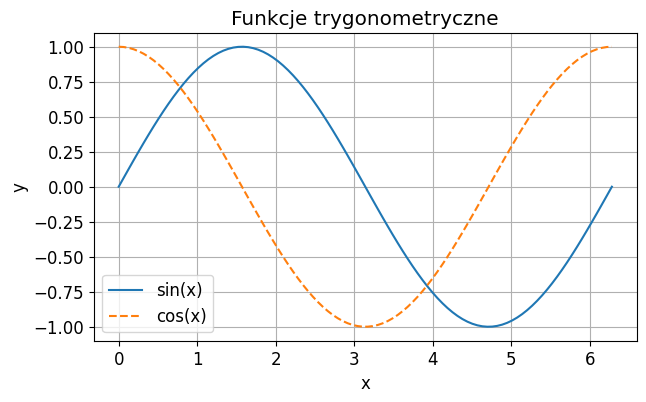

In [48]:
# Wykres liniowy
x = np.linspace(0, 2 * np.pi, 100)

fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label="sin(x)")
ax.plot(x, np.cos(x), "--", label="cos(x)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Funkcje trygonometryczne")
ax.grid(True)
ax.legend();

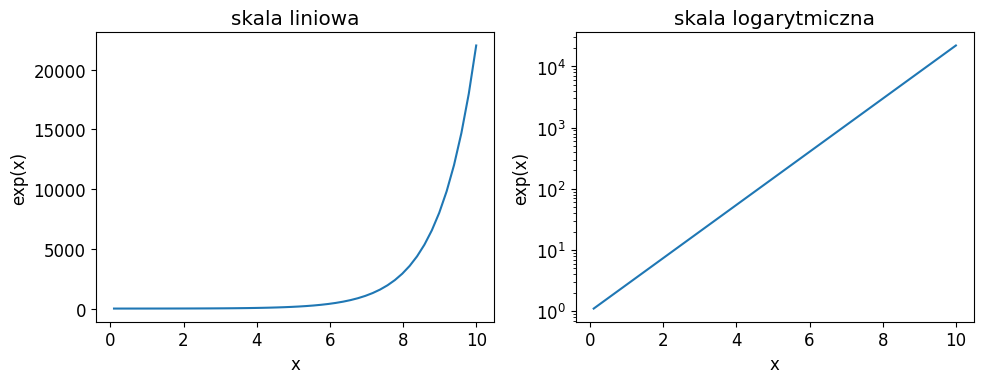

In [49]:
# Kilka paneli obok siebie; skala logarytmiczna
x = np.linspace(0.1, 10, 50)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(x, np.exp(x))
axs[0].set_title("skala liniowa")
axs[1].plot(x, np.exp(x))
axs[1].set_yscale("log")
axs[1].set_title("skala logarytmiczna")
for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("exp(x)")
fig.tight_layout()

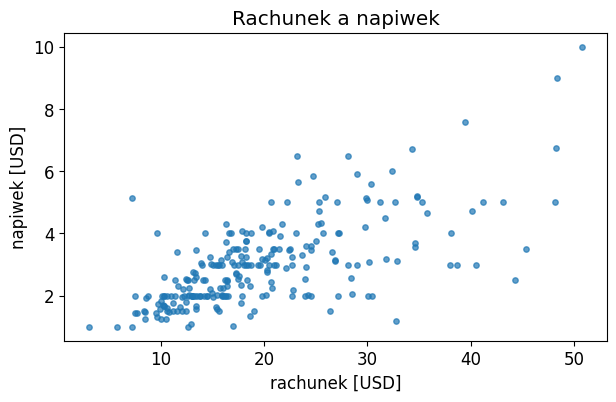

In [50]:
# Wykres punktowy
fig, ax = plt.subplots()
ax.scatter(df["total_bill"], df["tip"], s=15, alpha=0.7)
ax.set_xlabel("rachunek [USD]")
ax.set_ylabel("napiwek [USD]")
ax.set_title("Rachunek a napiwek");

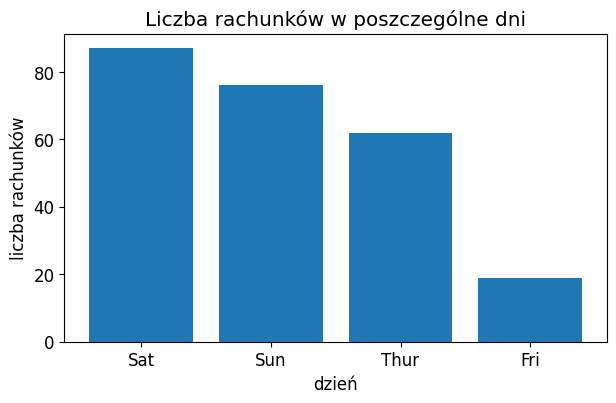

In [51]:
# Wykres słupkowy
liczba = df["day"].value_counts()

fig, ax = plt.subplots()
ax.bar(liczba.index, liczba.values)
ax.set_xlabel("dzień")
ax.set_ylabel("liczba rachunków")
ax.set_title("Liczba rachunków w poszczególne dni");

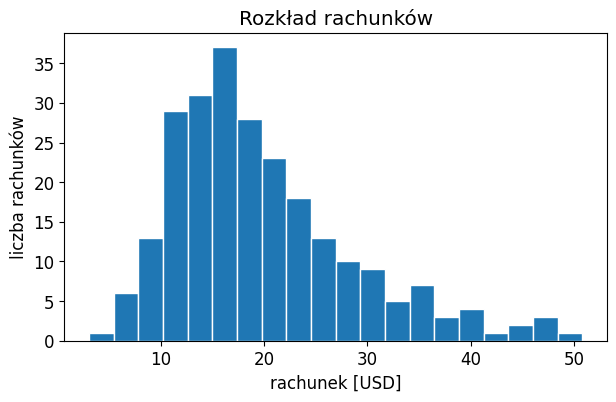

In [52]:
# Histogram — rozkład jednej zmiennej liczbowej
fig, ax = plt.subplots()
ax.hist(df["total_bill"], bins=20, edgecolor="white")
ax.set_xlabel("rachunek [USD]")
ax.set_ylabel("liczba rachunków")
ax.set_title("Rozkład rachunków");

### 🟢 Zadanie 9: lunch czy obiad?

Porównaj rozkład rachunków (`total_bill`) na lunchu i na obiedzie.

1. Narysuj dwa histogramy obok siebie (rysunek 10 × 4): lewy dla lunchu (`"Lunch"`), prawy dla obiadu (`"Dinner"`).
2. Oba histogramy muszą mieć **te same przedziały** (`bins=np.arange(0, 60, 5)`) i **wspólne osie** (`plt.subplots(..., sharex=True, sharey=True)`) — inaczej porównanie będzie mylące.
3. Na każdym panelu zaznacz średni rachunek pionową linią przerywaną (`ax.axvline(...)`) i podpisz ją w legendzie.
4. Dodaj tytuły i opisy osi z jednostkami.
5. W komórce tekstowej odpowiedz: kiedy rachunki są wyższe? Ile jest rachunków w każdej grupie?

🔵 **Dla ambitnych:** narysuj oba rozkłady na **jednym** wykresie (półprzezroczyste, `alpha=0.5`). Porównaj wersję z liczebnościami i z `density=True`. Dlaczego przy grupach różnej wielkości lepiej użyć `density=True`?

Lunch: n = 68  średnia = 17.17
Obiad: n = 176  średnia = 20.8


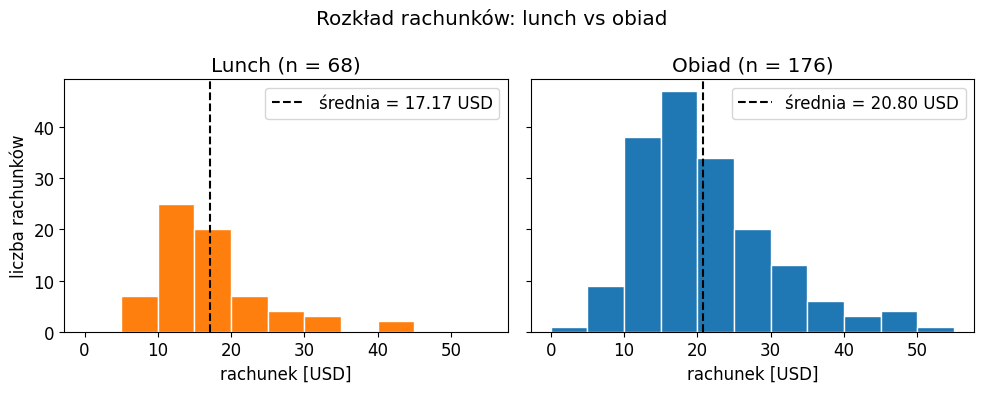

In [53]:
lunch = df[df["time"] == "Lunch"]["total_bill"]
obiad = df[df["time"] == "Dinner"]["total_bill"]
bins = np.arange(0, 60, 5)

fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, dane_, nazwa, kolor in zip(axs, [lunch, obiad], ["Lunch", "Obiad"], ["tab:orange", "tab:blue"]):
    ax.hist(dane_, bins=bins, color=kolor, edgecolor="white")
    ax.axvline(dane_.mean(), color="black", linestyle="--",
               label=f"średnia = {dane_.mean():.2f} USD")
    ax.set_title(f"{nazwa} (n = {len(dane_)})")
    ax.set_xlabel("rachunek [USD]")
    ax.legend()
axs[0].set_ylabel("liczba rachunków")
fig.suptitle("Rozkład rachunków: lunch vs obiad")
fig.tight_layout()

print("Lunch: n =", len(lunch), " średnia =", round(lunch.mean(), 2))
print("Obiad: n =", len(obiad), " średnia =", round(obiad.mean(), 2))

Rachunki są wyższe **na obiedzie** - średnio ok. **20,80 USD**, wobec ok. **17,17 USD** na lunchu; rozkład obiadowy jest też bardziej przesunięty w prawo i ma dłuższy „ogon” dużych rachunków (powyżej 35 USD prawie wyłącznie obiady). Rachunków z obiadu jest **176**, z lunchu **68** (razem 244) - obiadów jest ponad 2,5 raza więcej, dlatego słupki prawego histogramu są wyraźnie wyższe.

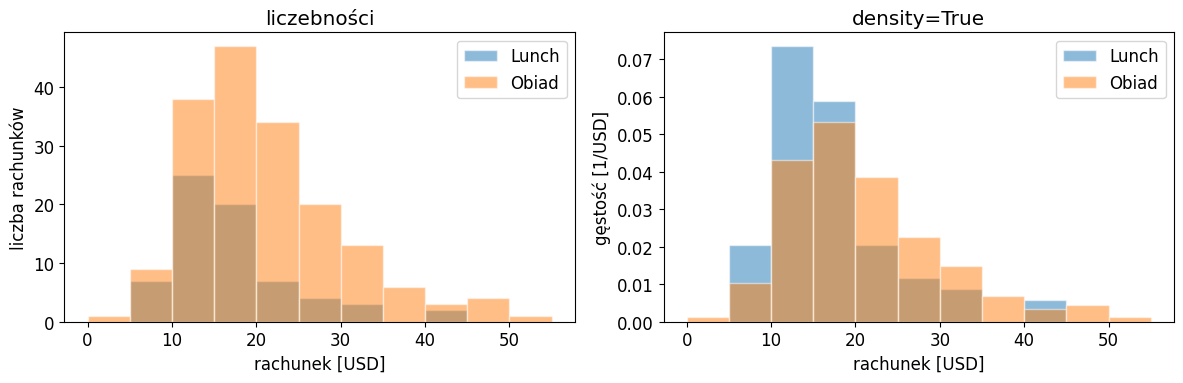

In [54]:
# 🔵 Oba rozkłady na jednym wykresie: liczebności vs gęstość
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, gest in zip(axs, [False, True]):
    ax.hist(lunch, bins=bins, alpha=0.5, density=gest, label="Lunch", edgecolor="white")
    ax.hist(obiad, bins=bins, alpha=0.5, density=gest, label="Obiad", edgecolor="white")
    ax.set_xlabel("rachunek [USD]")
    ax.set_ylabel("gęstość [1/USD]" if gest else "liczba rachunków")
    ax.set_title("density=True" if gest else "liczebności")
    ax.legend()
fig.tight_layout()

na wykresie liczebności obiad „dominuje” wszędzie po prostu dlatego, że obiadów jest 176, a lunchów tylko 68 - porównujemy wtedy wielkość grup, a nie kształt rozkładów. Przy `density=True` każdy histogram jest normowany tak, by jego pole wynosiło 1, więc widać, jaka **część** rachunków danej grupy wpada w dany przedział. Dopiero wtedy widać uczciwie, że lunch ma więcej rachunków w zakresie 10-20 USD, a obiad - więcej dużych rachunków

### 🟢 Zadanie 10: wykresy dla `tips` i ludności

1. Narysuj histogram napiwków (`tip`). Wypróbuj `bins` = 5, 20 i 50 — trzy panele obok siebie. Która liczba przedziałów najlepiej pokazuje kształt rozkładu?
2. Narysuj wykres liniowy liczby ludności Warszawy i Łodzi z zadania 8 (oba miasta na jednym wykresie, z legendą i znacznikami `marker="o"`).
3. Każdy wykres musi mieć tytuł i opisy osi z jednostkami.

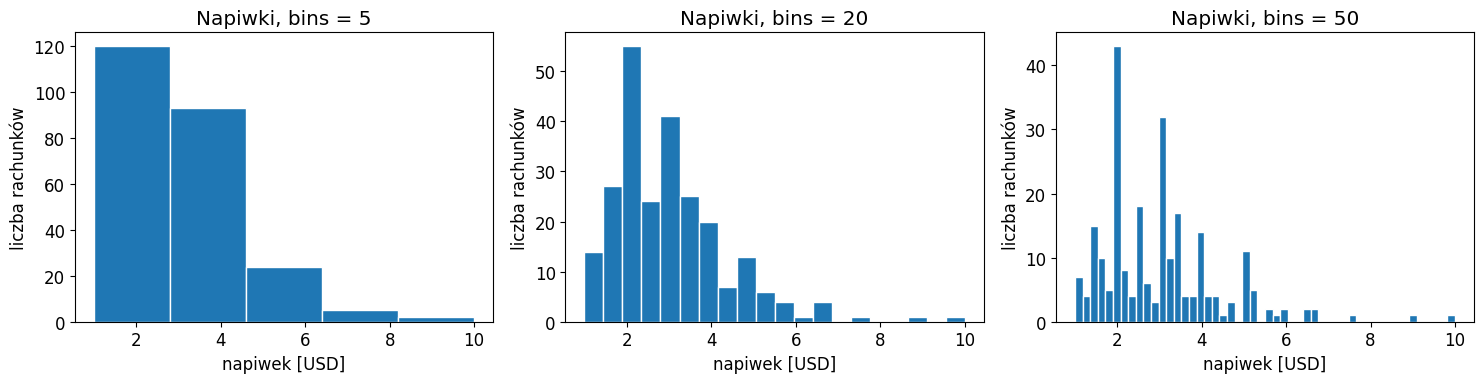

In [55]:
# 1. histogram napiwków dla różnych bins
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, b in zip(axs, [5, 20, 50]):
    ax.hist(df["tip"], bins=b, edgecolor="white")
    ax.set_title(f"Napiwki, bins = {b}")
    ax.set_xlabel("napiwek [USD]")
    ax.set_ylabel("liczba rachunków")
fig.tight_layout()

**Odpowiedź:** najlepiej sprawdza się **`bins = 20`**. Przy 5 przedziałach widać tylko, że większość napiwków jest mała - szczegóły znikają. Przy 50 przedziałach wykres jest „poszarpany” (dużo szumu, puste słupki, wyraźne piki na okrągłych kwotach 2, 3, 4 USD), co utrudnia ocenę kształtu. 20 przedziałów pokazuje wyraźnie rozkład prawostronnie skośny z maksimum ok. 2–3 USD.

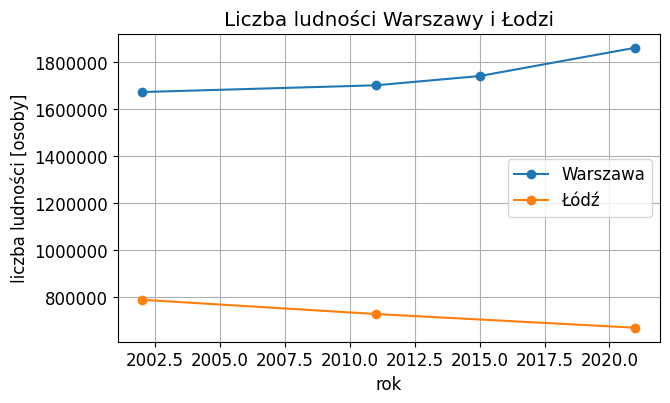

In [56]:
# 2. ludność Warszawy i Łodzi
fig, ax = plt.subplots()
ax.plot(ludnosc["Rok"], ludnosc["Warszawa"], marker="o", label="Warszawa")
lodz = ludnosc.dropna(subset=["Łódź"])     # pomijamy brak z 2015, żeby linia była ciągła
ax.plot(lodz["Rok"], lodz["Łódź"], marker="o", label="Łódź")
ax.set_title("Liczba ludności Warszawy i Łodzi")
ax.set_xlabel("rok")
ax.set_ylabel("liczba ludności [osoby]")
ax.ticklabel_format(axis="y", style="plain")
ax.grid(True)
ax.legend();

### 🔵 Zadanie 11 (dla ambitnych): rozkład normalny

1. Napisz funkcję gęstości rozkładu normalnego:
$$ f(x; \mu, \sigma) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right) $$
2. Dla trzech par $(\mu, \sigma)$: (0, 1), (0, 2), (2, 1) wygeneruj po 10 000 liczb (`rng.normal`) i narysuj ich histogram (`density=True`) razem z krzywą gęstości policzoną ze wzoru.
3. Trzy wykresy jeden pod drugim, każdy z tytułem zawierającym $\mu$ i $\sigma$, opisami osi i legendą.

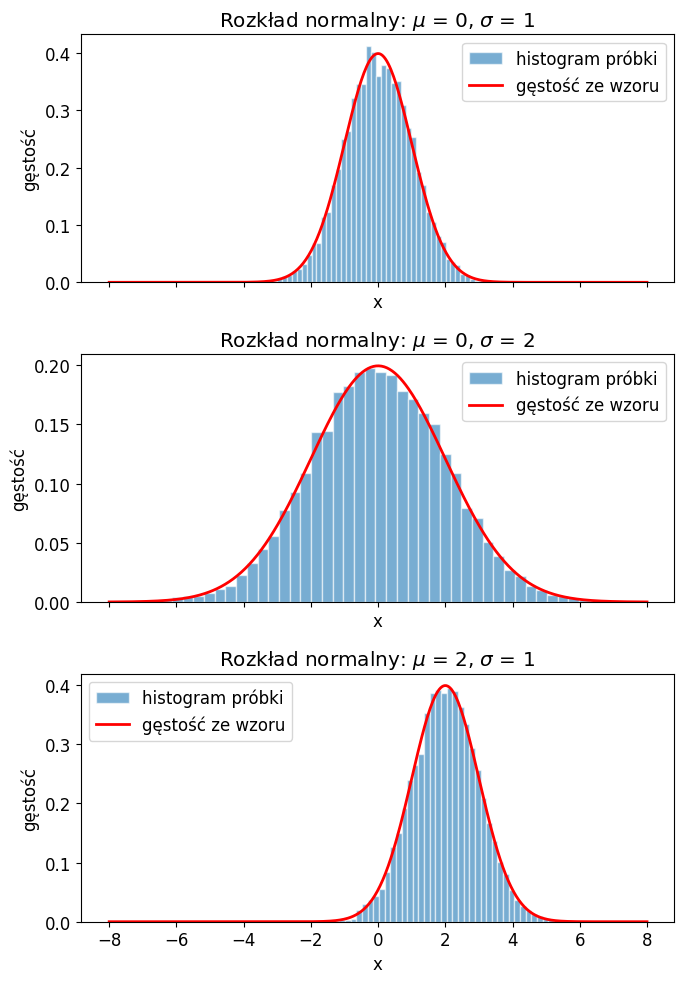

In [57]:
def gestosc_normalna(x, mu, sigma):
    """Gęstość rozkładu normalnego N(mu, sigma) w punktach x."""
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))


rng = np.random.default_rng(seed=0)
parametry = [(0, 1), (0, 2), (2, 1)]

fig, axs = plt.subplots(3, 1, figsize=(7, 10), sharex=True)
for ax, (mu, sigma) in zip(axs, parametry):
    probka = rng.normal(loc=mu, scale=sigma, size=10_000)
    ax.hist(probka, bins=50, density=True, alpha=0.6, edgecolor="white", label="histogram próbki")
    xs = np.linspace(-8, 8, 400)
    ax.plot(xs, gestosc_normalna(xs, mu, sigma), color="red", lw=2, label="gęstość ze wzoru")
    ax.set_title(f"Rozkład normalny: $\\mu$ = {mu}, $\\sigma$ = {sigma}")
    ax.set_xlabel("x")
    ax.set_ylabel("gęstość")
    ax.legend()
fig.tight_layout()

---
# Podsumowanie

Po tych zajęciach potrafisz:
- [ ] posługiwać się listami, słownikami, pętlami, funkcjami i list comprehension,
- [ ] tworzyć tablice NumPy, liczyć na nich bez pętli i losować liczby,
- [ ] wczytać dane do pandas, obejrzeć je (`head`, `info`, `describe`) i wybierać wiersze oraz kolumny,
- [ ] tworzyć nowe kolumny i zapisywać dane do pliku CSV,
- [ ] narysować wykres liniowy, punktowy, słupkowy i histogram — z opisami osi.

**Do oddania:** ten notatnik z rozwiązanymi zadaniami 🟢 w Twoim repozytorium na GitHubie.